In [1]:
%pip install "tabpfn==2.0.9" "scikit-learn==1.6.1"

  Using cached tabpfn-2.0.9-py3-none-any.whl.metadata (25 kB)
  Using cached scikit_learn-1.6.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (18 kB)
  Using cached einops-0.8.2-py3-none-any.whl.metadata (13 kB)
  Using cached huggingface_hub-0.36.2-py3-none-any.whl.metadata (15 kB)
  Using cached hf_xet-1.8.0-cp38-abi3-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (4.9 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached certifi-2026.11.20-py3-none-any.whl.metadata (2.5 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.5/13.5 MB 4.0 MB/s  0:00:03 eta 0:00:01
Using cached einops-0.8.2-py3-none-any.whl (65 kB)
Using cached huggingface_hub-0.36.2-py3-none-any.whl (566 kB)
Using cached hf_xet-1.8.0-cp38-abi3-manylinux2014_x86_64.manylinux_2_17

In [12]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from tabpfn import TabPFNClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (f1_score, accuracy_score, precision_score)
from sklearn.metrics import (recall_score, classification_report, confusion_matrix)
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score)

random_state = 42
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [13]:
# !pip install seaborn
# !pip install scikit-learn

In [14]:
training_data = pd.read_csv("../dataset/task1_static/train_features.csv")
training_labels = pd.read_csv("../dataset/task1_static/train_labels.csv")
training_data = training_data.merge(training_labels, left_on="flow_id", right_on="flow_id")

validation_data = pd.read_csv("../dataset/task1_static/validation_features.csv")
validation_labels = pd.read_csv("../dataset/task1_static/validation_labels.csv")
validation_data = validation_data.merge(validation_labels, left_on="flow_id", right_on="flow_id")

In [15]:
selected_features = ['transport', 'start_rel', 'duration', 'server_port', 'packet_count_down', 'bytes_up', 'mean_pkt_size_up', 'mean_pkt_size_down',
                     'std_pkt_size_up', 'std_pkt_size_down', 'mean_iat', 'std_iat', 'min_iat', 'max_iat', 'up_down_packet_ratio', 'up_down_byte_ratio']

low_association_features = ['std_pkt_size_down', 'up_down_byte_ratio', 'mean_iat',
                            'std_iat', 'min_iat', 'max_iat', 'server_port']

# set(selected_features) - set(low_assoiation_features)
reduced_features = [f for f in selected_features if f not in low_association_features]

label_encoder = LabelEncoder()
y_full = label_encoder.fit_transform(training_data["app"])
y_val = label_encoder.transform(validation_data["app"])

n_classes = len(label_encoder.classes_)
print(f"Number of classes: {n_classes}")

# TabPFN v2 is meant for <= 10k rows / 10 classes, we are far below that
# MAX_CONTEXT_ROWS kept from the tabfm notebook, does nothing here (247 rows)
MAX_CONTEXT_ROWS = 10_000

if MAX_CONTEXT_ROWS is not None and len(training_data) > MAX_CONTEXT_ROWS:
    train_idx, _ = train_test_split(
        training_data.index, train_size=MAX_CONTEXT_ROWS,
        stratify=training_data["app"], random_state=random_state
    )
    training_data_sampled = training_data.loc[train_idx]
else:
    training_data_sampled = training_data

X_train = training_data_sampled[selected_features].copy()
y_train = label_encoder.transform(training_data_sampled["app"])
X_val = validation_data[selected_features].copy()

X_train['transport'] = (X_train['transport'] == 'udp').astype(int)
X_val['transport'] = (X_val['transport'] == 'udp').astype(int)

Number of classes: 6


### Zero-shot evaluation helpers

In [16]:
def report_zero_shot(model, Xtr, ytr, Xte, yte, experiment_name):
    start = time.time()
    model.fit(Xtr, ytr)
    elapsed_fit = time.time() - start

    start = time.time()
    proba = model.predict_proba(Xte)
    elapsed_pred = time.time() - start
    pred = proba.argmax(axis=1)

    print("\n", experiment_name)
    print("Test macro-F1:", f1_score(yte, pred, average='macro'))
    print("Test accuracy:", accuracy_score(yte, pred))
    print("Test balanced accuracy:", balanced_accuracy_score(yte, pred))
    print("Test AUC-ROC (ovr):", roc_auc_score(yte, proba, multi_class='ovr'))
    print(classification_report(yte, pred, zero_division=0))

    labels = np.unique(np.concatenate([yte, pred]))
    cm = confusion_matrix(yte, pred, labels=labels)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_encoder.inverse_transform(labels),
                yticklabels=label_encoder.inverse_transform(labels))
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion Matrix - {experiment_name}')
    plt.tight_layout(); plt.show()

    print(f"Fit time: {elapsed_fit:.2f}s | Predict time: {elapsed_pred:.2f}s")
    return model, pred, proba, {"fit_s": elapsed_fit, "predict_s": elapsed_pred}

In [17]:
def run_experiment(model_name, feature_list):
    Xtr = X_train[feature_list].copy()
    Xte = X_val[feature_list].copy()
    clf = TabPFNClassifier(device=device, random_state=random_state)
    experiment_name = model_name + ('_E1_16features' if len(feature_list) == 16 else '_E2_reduced')
    return report_zero_shot(clf, Xtr, y_train, Xte, y_val, experiment_name)

In [18]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

### Experiment-1: All 16 selected features


 tabpfn_E1_16features
Test macro-F1: 0.7219238653315733
Test accuracy: 0.8554216867469879
Test balanced accuracy: 0.7189995189995191
Test AUC-ROC (ovr): 0.949239624778636
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.84      0.94      0.89        33
           2       1.00      0.80      0.89         5
           3       0.82      0.90      0.86        10
           4       1.00      0.89      0.94        18
           5       0.73      0.79      0.76        14

    accuracy                           0.86        83
   macro avg       0.73      0.72      0.72        83
weighted avg       0.83      0.86      0.84        83



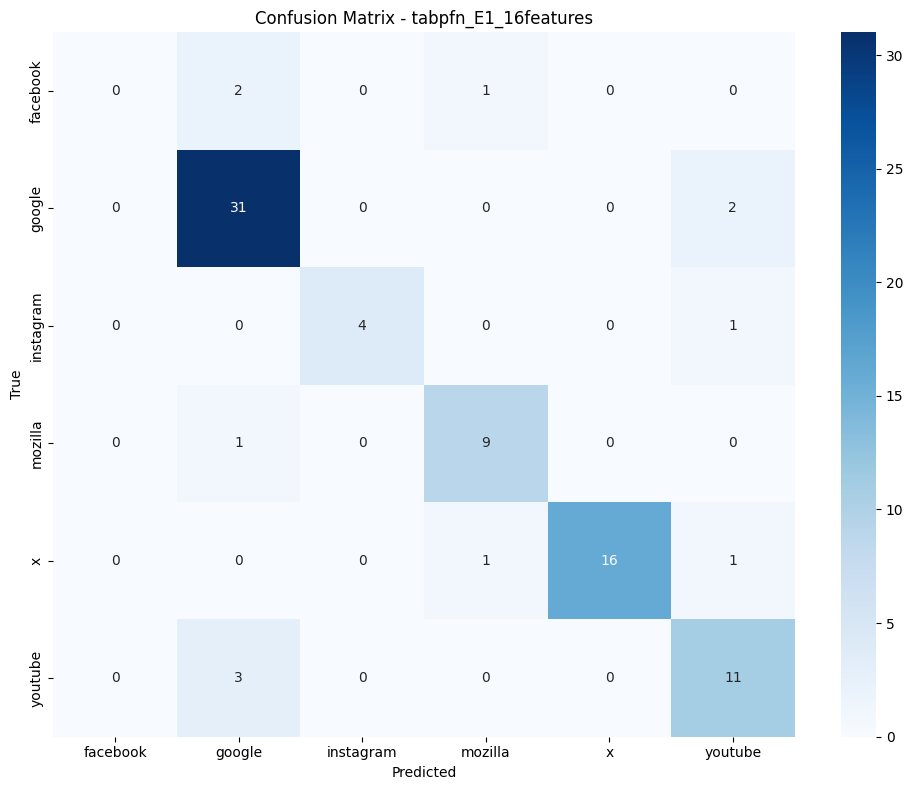

Fit time: 0.05s | Predict time: 0.68s


In [19]:
model_e1, pred_e1, proba_e1, timing_e1 = run_experiment('tabpfn', selected_features)

### Experiment-2: Reduced feature set (9 features)


 tabpfn_E2_reduced
Test macro-F1: 0.7053741347219608
Test accuracy: 0.8433734939759037
Test balanced accuracy: 0.7097402597402599
Test AUC-ROC (ovr): 0.9431074414137249
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.86      0.94      0.90        33
           2       1.00      0.80      0.89         5
           3       0.64      0.90      0.75        10
           4       1.00      0.83      0.91        18
           5       0.79      0.79      0.79        14

    accuracy                           0.84        83
   macro avg       0.71      0.71      0.71        83
weighted avg       0.83      0.84      0.83        83



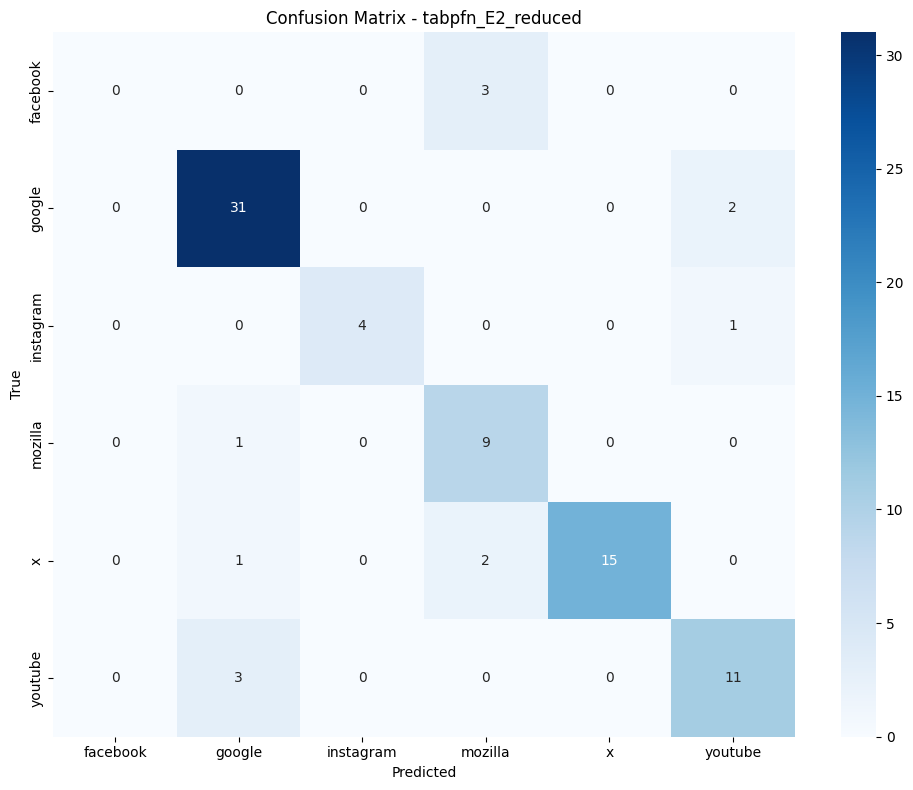

Fit time: 0.06s | Predict time: 0.07s


In [20]:
model_e2, pred_e2, proba_e2, timing_e2 = run_experiment('tabpfn', reduced_features)

## Compare feature configurations

In [9]:
rows = []
for name, pred, proba, timing in [('E1 - 16 features', pred_e1, proba_e1, timing_e1),
                                  ('E2 - reduced features', pred_e2, proba_e2, timing_e2)]:
    rows.append({'Experiment': name,
                 'Accuracy': accuracy_score(y_val, pred),
                 'Balanced_Accuracy': balanced_accuracy_score(y_val, pred),
                 'F1_weighted': f1_score(y_val, pred, average='weighted'),
                 'Macro_F1': f1_score(y_val, pred, average='macro'),
                 'AUC_ROC': roc_auc_score(y_val, proba, multi_class='ovr'),
                 'Fit_s': timing['fit_s'], 'Predict_s': timing['predict_s']})
comparison = pd.DataFrame(rows)
display(comparison.round(4))
comparison.to_csv('feature_ablation_comparison_tabpfn.csv', index=False)

,Experiment,Accuracy,Balanced_Accuracy,F1_weighted,Macro_F1,AUC_ROC,Fit_s,Predict_s
0,E1 - 16 features,0.8554,0.7190,0.8410,0.7219,0.9490,0.3266,4.2465
1,E2 - reduced features,0.8434,0.7097,0.8308,0.7054,0.9438,0.1264,2.5502
